# Symbolic Regression for Reaction-Rate Equation Discovery

This notebook compares preprocessing and symbolic-regression methods using six benchmark rate laws and multiple initial concentrations. Training, validation, and final testing are separated by initial concentration to assess generalization beyond the concentration range used for fitting.

## 1. Environment Setup

Install the packages in the active Jupyter environment if they are not already available.

```python
%pip install pysr numpy pandas matplotlib scipy sympy scikit-learn
```

The smoothing-spline GCV implementation uses `scipy.interpolate.make_smoothing_spline`, available in SciPy 1.10 and later. PySR also requires its Julia backend, which is initialized on first use.

## 2. Import Libraries

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp

from itertools import combinations
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.interpolate import make_smoothing_spline
from scipy.integrate import solve_ivp
from sklearn.metrics import mean_squared_error, mean_absolute_error

pd.set_option("display.max_colwidth", 120)

## 3. Load and Normalize the Generated Dataset

In [2]:
data_dir_candidates = [
    Path("reaction_data"),
    Path("reaction_data_generated"),
    Path("../reaction_data"),
    Path("../reaction_data_generated")
]

data_dir = next(
    (
        candidate for candidate in data_dir_candidates
        if (candidate / "reaction_dataset.csv").exists()
        and (candidate / "rate_law_parameters.csv").exists()
    ),
    None
)

if data_dir is None:
    searched_paths = [str(path.resolve()) for path in data_dir_candidates]
    raise FileNotFoundError(
        "Could not find reaction_dataset.csv and rate_law_parameters.csv. "
        f"Searched: {searched_paths}"
    )

df = pd.read_csv(data_dir / "reaction_dataset.csv")
parameters_df = pd.read_csv(data_dir / "rate_law_parameters.csv")

TRAIN_INITIAL_CONCENTRATIONS = [0.025, 0.05]
HELD_OUT_INITIAL_CONCENTRATION = 0.075

reaction_id_map = {
    "first_order": "First_Order",
    "second_order": "Second_Order",
    "fractional_order_1_5": "Fractional_Order",
    "saturation": "Saturation",
    "fourth_order": "Fourth_Order",
    "zero_order": "Zero_Order"
}

reaction_name_map = {
    "First order": "First_Order",
    "Second order": "Second_Order",
    "Fractional order (1.5)": "Fractional_Order",
    "Saturation kinetics": "Saturation",
    "Fourth order": "Fourth_Order",
    "Zero order": "Zero_Order"
}

column_aliases = {
    "CA_true_mol_L": "CA_true",
    "CA_observed_mol_L": "CA_observed",
    "noise_level_pct_of_CA0": "noise_level",
    "replicate_id": "replicate"
}

df = df.rename(columns=column_aliases)

if "reaction" not in df.columns:
    if "rate_law_id" in df.columns:
        df["reaction"] = df["rate_law_id"].map(reaction_id_map)
    elif "rate_law_name" in df.columns:
        df["reaction"] = df["rate_law_name"].map(reaction_name_map)

if "reaction" in df.columns:
    df["reaction"] = df["reaction"].replace(reaction_name_map)

required_columns = {
    "reaction", "time_min", "noise_level", "replicate",
    "initial_concentration_mol_L", "CA_true", "CA_observed"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing dataset columns: {sorted(missing_columns)}")

if df["reaction"].isna().any():
    raise ValueError("Some reaction identifiers could not be mapped.")

if df["noise_level"].max() > 1:
    df["noise_level"] = df["noise_level"] / 100.0

parameter_aliases = {
    "Vmax_mol_L_min": "Vmax",
    "K_mol_L": "K"
}
parameters_df = parameters_df.rename(columns=parameter_aliases)

if "reaction" not in parameters_df.columns:
    if "rate_law_id" in parameters_df.columns:
        parameters_df["reaction"] = parameters_df["rate_law_id"].map(reaction_id_map)
    elif "rate_law_name" in parameters_df.columns:
        parameters_df["reaction"] = parameters_df["rate_law_name"].map(reaction_name_map)

if "reaction" in parameters_df.columns:
    parameters_df["reaction"] = parameters_df["reaction"].replace(reaction_name_map)

for parameter in ["k", "Vmax", "K"]:
    if parameter not in parameters_df.columns:
        parameters_df[parameter] = np.nan

parameters_df = parameters_df.drop_duplicates("reaction").reset_index(drop=True)
parameter_lookup = parameters_df.set_index("reaction")[["k", "Vmax", "K"]].to_dict("index")

print("Dataset path:", (data_dir / "reaction_dataset.csv").resolve())
print("Dataset shape:", df.shape)
print("Reactions:", sorted(df["reaction"].unique()))
print("Noise levels:", sorted(df["noise_level"].unique()))
print("Initial concentrations:", sorted(df["initial_concentration_mol_L"].unique()))
print("Training initial concentrations:", TRAIN_INITIAL_CONCENTRATIONS)
print("Held-out initial concentration:", HELD_OUT_INITIAL_CONCENTRATION)
print("Replicates:", sorted(df["replicate"].unique()))
print("Missing values:", int(df[list(required_columns)].isna().sum().sum()))

display(df.head())
display(parameters_df[["reaction", "k", "Vmax", "K"]])

Dataset path: C:\F\CHE657 Term Project\reaction_data\reaction_dataset.csv
Dataset shape: (34848, 7)
Reactions: ['First_Order', 'Fourth_Order', 'Fractional_Order', 'Saturation', 'Second_Order', 'Zero_Order']
Noise levels: [np.float64(0.0), np.float64(0.01), np.float64(0.03), np.float64(0.05)]
Initial concentrations: [np.float64(0.025), np.float64(0.05), np.float64(0.075)]
Training initial concentrations: [0.025, 0.05]
Held-out initial concentration: 0.075
Replicates: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Missing values: 0


,reaction,time_min,noise_level,replicate,initial_concentration_mol_L,CA_true,CA_observed
0,First_Order,0.00,0.0,0,0.025,0.025000,0.025000
1,First_Order,0.25,0.0,0,0.025,0.024383,0.024383
2,First_Order,0.50,0.0,0,0.025,0.023781,0.023781
3,First_Order,0.75,0.0,0,0.025,0.023194,0.023194
4,First_Order,1.00,0.0,0,0.025,0.022621,0.022621


,reaction,k,Vmax,K
0,First_Order,0.100000,NaN,NaN
1,Second_Order,2.000000,NaN,NaN
2,Fractional_Order,0.447214,NaN,NaN
3,Saturation,NaN,0.007,0.02
4,Fourth_Order,800.000000,NaN,NaN
5,Zero_Order,0.005000,NaN,NaN


## 4. Define the Benchmark Rate Laws

The target is the disappearance rate of reactant A:

\[
r=-r_A=-\frac{dC_A}{dt}.
\]

The six benchmark expressions are:

| Reaction | Rate law |
|---|---|
| First order | \(r=kC_A\) |
| Second order | \(r=kC_A^2\) |
| Fractional order | \(r=kC_A^{1.5}\) |
| Saturation | \(r=V_{\max}C_A/(K+C_A)\) |
| Fourth order | \(r=kC_A^4\) |
| Zero order | \(r=k\) |

The numerical parameters and units are stored in `rate_law_parameters.csv`.

In [3]:
def calculate_rate(CA, reaction, params):
    if reaction == "First_Order":
        return params["k"] * CA
    if reaction == "Second_Order":
        return params["k"] * CA**2
    if reaction == "Fractional_Order":
        return params["k"] * CA**1.5
    if reaction == "Saturation":
        return params["Vmax"] * CA / (params["K"] + CA)
    if reaction == "Fourth_Order":
        return params["k"] * CA**4
    if reaction == "Zero_Order":
        return params["k"]
    raise ValueError(f"Unknown reaction: {reaction}")


def calculate_rate_array(concentrations, reaction, params):
    return np.asarray(
        [calculate_rate(value, reaction, params) for value in concentrations],
        dtype=float
    )

## 5. Construct the Clean Ground-Truth Dataset

The clean-data baseline uses only the two training initial concentrations. The held-out initial concentration is reserved for the final noisy-data test.

In [4]:
df_clean = df.loc[
    (df["noise_level"] == 0)
    & df["initial_concentration_mol_L"].isin(TRAIN_INITIAL_CONCENTRATIONS)
].copy()

df_clean["rate_true"] = [
    calculate_rate(value, reaction, parameter_lookup[reaction])
    for value, reaction in zip(df_clean["CA_true"], df_clean["reaction"])
]

zero_order_mask = df_clean["reaction"] == "Zero_Order"
zero_order_scale = df_clean.loc[zero_order_mask, "CA_true"].abs().max()
depletion_tolerance = 1e-8 * zero_order_scale

df_clean = df_clean.loc[
    ~(
        zero_order_mask
        & (df_clean["CA_true"] <= depletion_tolerance)
    )
].copy()

df_clean = df_clean.sort_values(
    ["reaction", "initial_concentration_mol_L", "time_min"]
).reset_index(drop=True)

print("Clean dataset shape:", df_clean.shape)
display(df_clean.groupby("reaction").size().rename("observations"))
display(df_clean.head())

Clean dataset shape: (1270, 8)


reaction
First_Order         242
Fourth_Order        242
Fractional_Order    242
Saturation          242
Second_Order        242
Zero_Order           60
Name: observations, dtype: int64

,reaction,time_min,noise_level,replicate,initial_concentration_mol_L,CA_true,CA_observed,rate_true
0,First_Order,0.00,0.0,0,0.025,0.025000,0.025000,0.002500
1,First_Order,0.25,0.0,0,0.025,0.024383,0.024383,0.002438
2,First_Order,0.50,0.0,0,0.025,0.023781,0.023781,0.002378
3,First_Order,0.75,0.0,0,0.025,0.023194,0.023194,0.002319
4,First_Order,1.00,0.0,0,0.025,0.022621,0.022621,0.002262


## 6. Visualize the Ground-Truth Rate Laws

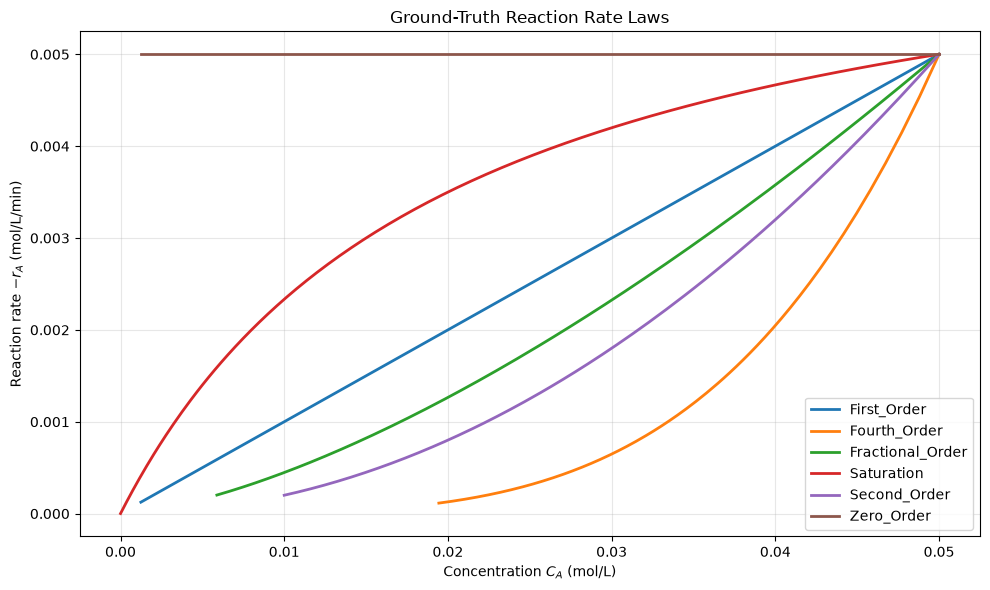

In [5]:
plt.figure(figsize=(10, 6))

for reaction, subset in df_clean.groupby("reaction"):
    subset = subset.sort_values("CA_true")
    plt.plot(
        subset["CA_true"],
        subset["rate_true"],
        label=reaction,
        linewidth=2
    )

plt.xlabel("Concentration $C_A$ (mol/L)")
plt.ylabel("Reaction rate $-r_A$ (mol/L/min)")
plt.title("Ground-Truth Reaction Rate Laws")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Configure PySR

A separate symbolic-regression model is trained for each benchmark reaction. The same configuration is used across reactions so their clean-data results are comparable.

In [6]:
def create_pysr_model(verbosity=0):
    # Delay Julia initialization until symbolic regression is actually requested.
    try:
        from pysr import PySRRegressor
    except Exception as exc:
        raise RuntimeError("PySR could not initialize its Julia backend; resolve the Julia environment lock/setup before fitting.") from exc
    return PySRRegressor(
        niterations=100,
        populations=15,
        population_size=33,
        maxsize=20,
        binary_operators=["+", "-", "*", "/", "^"],
        constraints={"^": (-1, 1)},
        model_selection="best",
        verbosity=verbosity
    )


## 8. Run the Clean-Data PySR Baseline

For each reaction, PySR receives clean concentration and exact rate data from the training initial concentrations only. This establishes an ideal-condition reference and does not use the held-out initial concentration.

In [7]:
clean_models = {}

for reaction, subset in df_clean.groupby("reaction"):
    X = subset[["CA_true"]].to_numpy(dtype=float)
    y = subset["rate_true"].to_numpy(dtype=float)

    model = create_pysr_model(verbosity=0)
    model.fit(X, y)
    clean_models[reaction] = model

    print(f"Completed: {reaction}")

Completed: First_Order
Completed: Fourth_Order
Completed: Fractional_Order
Completed: Saturation
Completed: Second_Order
Completed: Zero_Order


## 9. Summarize the Clean-Data PySR Equations

In [8]:
baseline_results = []

for reaction, model in clean_models.items():
    equations = model.equations_
    best = equations.loc[equations["loss"].idxmin()]

    baseline_results.append({
        "Reaction": reaction,
        "Lowest-loss equation": best["equation"],
        "PySR loss": best["loss"],
        "Complexity": best["complexity"],
        "Score": best["score"]
    })

baseline_df = pd.DataFrame(baseline_results)
display(baseline_df)

,Reaction,Lowest-loss equation,PySR loss,Complexity,Score
0,First_Order,x0 * 0.1,5.700847e-21,3,16.496537
1,Fourth_Order,x0 * (39.217884 * (x0 * ((x0 * 57.055042) * (x0 * 0.35752943)))),9.104948e-21,13,0.027825
2,Fractional_Order,((x0 * (x0 * ((x0 / x0) / x0))) * ((x0 * 4.9990773) ^ -0.50009054)) * x0,1.370054e-13,17,0.000032
3,Saturation,0.03675482 / (5.237138 - (-0.10532479 / x0)),2.589994e-12,7,4.675499
4,Second_Order,(x0 / (x0 * x0)) * ((x0 + x0) * (x0 * x0)),4.077659e-21,13,0.003073
5,Zero_Order,0.005,0.000000e+00,1,0.000000


## 10. Equation Simplification

The simplifier generates candidates from algebraic transformations, additive-term subsets, and numerator or denominator subsets of rational expressions. It refits multiplicative coefficients only; nonlinear powers and structures remain fixed.

The clean-data section below selects its simplified equation on the same clean trajectories used to fit coefficients. That is an in-sample implementation baseline, not an accuracy estimate. Its BIC-style score also treats time samples as if they were independent, although adjacent trajectory points are correlated, so use the score only to shortlist candidates. For noisy discovery, use this simplifier to generate training-only candidates, then choose among originals and simplifications by held-out ODE trajectory error in Section 14. The final initial-concentration test remains untouched until Section 15.


### 10.1 Define the Candidate-Generation and Fitting Functions

In [9]:
x0 = sp.symbols("x0")


def subset_expressions(terms, max_terms=5):
    terms = list(terms)
    if not terms:
        return []
    if len(terms) > max_terms:
        return [sp.Add(*terms)] + terms
    return [
        sp.Add(*subset)
        for size in range(1, len(terms) + 1)
        for subset in combinations(terms, size)
    ]


def evaluate_expression(expression, X):
    function = sp.lambdify(x0, expression, modules="numpy")
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        values = np.asarray(function(X))
    if np.iscomplexobj(values):
        raise ValueError("Expression produced complex values.")
    values = np.asarray(values, dtype=float)
    return np.broadcast_to(values, X.shape)


def fit_candidate_coefficients(candidate, X, y):
    expanded = sp.expand(candidate)
    terms = sp.Add.make_args(expanded)
    bases = [term.as_coeff_Mul()[1] for term in terms]

    columns = [evaluate_expression(base, X) for base in bases]
    design_matrix = np.column_stack(columns)

    if not np.all(np.isfinite(design_matrix)):
        return None

    coefficients, _, rank, _ = np.linalg.lstsq(
        design_matrix, y, rcond=None
    )

    predictions = design_matrix @ coefficients
    if not np.all(np.isfinite(predictions)):
        return None

    fitted_expression = sp.simplify(
        sum(
            sp.Float(float(coefficient), 12) * base
            for coefficient, base in zip(coefficients, bases)
        )
    )

    rss = float(np.sum((y - predictions) ** 2))
    complexity = int(sp.count_ops(fitted_expression))
    return fitted_expression, rss, int(rank), complexity


def automatic_simplify(
    equation,
    X,
    y,
    max_terms=5,
    complexity_weight=1.0
):
    X = np.asarray(X, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float).reshape(-1)

    if X.shape != y.shape:
        raise ValueError("X and y must have the same number of observations.")
    if X.size == 0:
        raise ValueError("X and y cannot be empty.")
    if not np.all(np.isfinite(X)) or not np.all(np.isfinite(y)):
        raise ValueError("X and y must contain only finite values.")

    expression = sp.sympify(equation)
    candidates = {}

    def add_candidate(candidate):
        try:
            candidate = sp.cancel(candidate)
            if candidate not in (sp.nan, sp.zoo, sp.oo, -sp.oo):
                candidates[sp.srepr(candidate)] = candidate
        except (sp.SympifyError, ValueError, TypeError):
            return

    algebraic_forms = [
        expression,
        sp.simplify(expression),
        sp.factor(expression),
        sp.cancel(expression),
        sp.together(expression),
        sp.expand(expression)
    ]

    for form in algebraic_forms:
        add_candidate(form)

    expanded_expression = sp.expand(expression)
    additive_terms = sp.Add.make_args(expanded_expression)

    for candidate in subset_expressions(additive_terms, max_terms):
        add_candidate(candidate)

    numerator, denominator = sp.fraction(sp.together(expression))
    numerator_terms = sp.Add.make_args(sp.expand(numerator))
    denominator_terms = sp.Add.make_args(sp.expand(denominator))

    numerator_candidates = subset_expressions(numerator_terms, max_terms)
    denominator_candidates = subset_expressions(denominator_terms, max_terms)

    for numerator_candidate in numerator_candidates:
        add_candidate(numerator_candidate / denominator)

    for denominator_candidate in denominator_candidates:
        if denominator_candidate != 0:
            add_candidate(numerator / denominator_candidate)

    if len(numerator_terms) <= 3 and len(denominator_terms) <= 3:
        for numerator_candidate in numerator_candidates:
            for denominator_candidate in denominator_candidates:
                if denominator_candidate != 0:
                    add_candidate(numerator_candidate / denominator_candidate)

    n = len(y)
    signal_scale = max(float(np.mean(y**2)), np.finfo(float).tiny)
    residual_floor = np.finfo(float).eps * signal_scale
    results = []

    for candidate in candidates.values():
        try:
            fitted = fit_candidate_coefficients(candidate, X, y)
            if fitted is None:
                continue

            fitted_expression, rss, parameter_count, complexity = fitted
            rss_per_observation = max(rss / n, residual_floor)
            bic_style = (
                n * np.log(rss_per_observation)
                + parameter_count * np.log(n)
            )
            selection_score = (
                bic_style
                + complexity_weight * complexity * np.log(n)
            )

            results.append({
                "equation": fitted_expression,
                "terms": len(sp.Add.make_args(sp.expand(fitted_expression))),
                "complexity": complexity,
                "RSS": rss,
                "BIC-style score": bic_style,
                "Selection Score": selection_score
            })

        except (
            ValueError, TypeError, OverflowError,
            ZeroDivisionError, FloatingPointError
        ):
            continue

    if not results:
        raise ValueError("No valid candidate equations were generated.")

    results_df = pd.DataFrame(results)
    results_df["equation_key"] = results_df["equation"].map(sp.srepr)
    results_df = results_df.drop_duplicates("equation_key")
    results_df = results_df.drop(columns="equation_key")
    results_df = results_df.sort_values(
        ["Selection Score", "complexity", "RSS"]
    ).reset_index(drop=True)

    return results_df.iloc[0], results_df

### 10.2 Simplify the Complete Clean-Data PySR Libraries

In [10]:
def simplify_pysr_library(model, X, y):
    summaries = []
    candidate_tables = {}

    for equation_index, row in model.equations_.iterrows():
        best, candidates = automatic_simplify(
            row["sympy_format"], X, y
        )
        candidate_tables[equation_index] = candidates

        summaries.append({
            "Source equation": row["sympy_format"],
            "Source complexity": row["complexity"],
            "Simplified equation": best["equation"],
            "Terms": best["terms"],
            "Complexity": best["complexity"],
            "RSS": best["RSS"],
            "BIC-style score": best["BIC-style score"],
            "Selection Score": best["Selection Score"]
        })

    summary_df = pd.DataFrame(summaries).sort_values(
        ["Selection Score", "Complexity", "RSS"]
    ).reset_index(drop=True)

    return summary_df.iloc[0], summary_df, candidate_tables


automatic_results = []
all_candidates = {}

for reaction, model in clean_models.items():
    subset = df_clean.loc[df_clean["reaction"] == reaction]
    X = subset["CA_true"].to_numpy(dtype=float)
    y = subset["rate_true"].to_numpy(dtype=float)

    lowest_loss = model.equations_.loc[
        model.equations_["loss"].idxmin(), "sympy_format"
    ]

    best, summary, candidate_tables = simplify_pysr_library(
        model, X, y
    )

    all_candidates[reaction] = candidate_tables

    automatic_results.append({
        "Reaction": reaction,
        "PySR lowest-loss equation": lowest_loss,
        "Simplifier source equation": best["Source equation"],
        "Simplified equation": best["Simplified equation"],
        "Complexity": best["Complexity"],
        "RSS": best["RSS"],
        "Selection Score": best["Selection Score"]
    })

automatic_df = pd.DataFrame(automatic_results)
display(automatic_df)

,Reaction,PySR lowest-loss equation,Simplifier source equation,Simplified equation,Complexity,RSS,Selection Score
0,First_Order,x0*0.1,x0*0.1,0.1*x0,1,4.587220e-35,-11819.873314
1,Fourth_Order,x0*39.217884*x0*x0*57.055042*x0*0.35752943,x0*x0*800.0*x0*x0,800.0*x0**4,2,5.194032e-36,-12080.159258
2,Fractional_Order,x0*x0*x0*x0/(x0*x0*(x0*4.9990773)**0.50009054),x0*x0/(x0*4.9990773)**0.50009054,0.447073340964*x0**1.49990946,2,7.047699e-13,-8083.235150
3,Saturation,0.03675482/(5.237138 - (-1)*0.10532479/x0),0.03675482/(5.237138 - (-1)*0.10532479/x0),0.00701819980448*x0/(1.0*x0 + 0.0201111351276212),4,6.266199e-10,-6429.023056
4,Second_Order,x0*x0*x0*(x0 + x0)/((x0*x0)),x0/((0.5/x0)),2.0*x0**2,2,1.756776e-35,-11939.813589
5,Zero_Order,0.00500000000000000,0.00500000000000000,0.00500000000000,0,4.513898e-35,-2794.322943


### 10.3 Compare Original and Simplified Clean-Data Equations

The following comparison is in-sample because the clean trajectories were used to fit the candidate equations. It is an implementation check for the simplifier, not evidence of generalization.

In [11]:
def predict_expression(expression, X):
    function = sp.lambdify(x0, sp.sympify(expression), modules="numpy")
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        predictions = np.asarray(function(X))
    if np.iscomplexobj(predictions):
        raise ValueError("Expression produced complex predictions.")
    return np.broadcast_to(
        np.asarray(predictions, dtype=float),
        np.shape(X)
    )


comparison_results = []

for _, row in automatic_df.iterrows():
    reaction = row["Reaction"]
    subset = df_clean.loc[df_clean["reaction"] == reaction]
    X = subset["CA_true"].to_numpy(dtype=float)
    y = subset["rate_true"].to_numpy(dtype=float)

    original_predictions = predict_expression(
        row["PySR lowest-loss equation"], X
    )
    simplified_predictions = predict_expression(
        row["Simplified equation"], X
    )

    comparison_results.append({
        "Reaction": reaction,
        "Original RMSE": np.sqrt(mean_squared_error(y, original_predictions)),
        "Simplified RMSE": np.sqrt(mean_squared_error(y, simplified_predictions)),
        "Original MAE": mean_absolute_error(y, original_predictions),
        "Simplified MAE": mean_absolute_error(y, simplified_predictions)
    })

automatic_comparison_df = pd.DataFrame(comparison_results)
display(automatic_comparison_df)

,Reaction,Original RMSE,Simplified RMSE,Original MAE,Simplified MAE
0,First_Order,1.796182e-18,1.796182e-18,1.317395e-18,1.317395e-18
1,Fourth_Order,7.470918e-12,1.587191e-19,4.350435e-12,8.265922e-20
2,Fractional_Order,3.701441e-07,5.396547e-08,3.003756e-07,4.854468e-08
3,Saturation,1.609337e-06,1.609142e-06,1.112962e-06,1.109920e-06
4,Second_Order,1.192862e-19,0.000000e+00,4.894590e-20,0.000000e+00
5,Zero_Order,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


## 11. Noise-Reduction Methods

Only measured concentration and time values enter the preprocessing functions. Clean simulated concentrations and exact rates are joined back later, exclusively for retrospective evaluation.

Three methods are compared:

1. Raw numerical differentiation.
2. Fixed-window Savitzky–Golay smoothing and differentiation.
3. Smoothing-spline fitting with the smoothing parameter selected by generalized cross-validation (GCV).

GCV selects the spline regularization parameter from the noisy trajectory. It does not use the clean reference data.

### 11.1 Define the Preprocessing Settings

In [12]:
SG_WINDOW = 11
SG_POLYORDER = 3
EDGE_TRIM = SG_WINDOW // 2

if SG_WINDOW % 2 == 0:
    raise ValueError("SG_WINDOW must be odd.")
if SG_POLYORDER >= SG_WINDOW:
    raise ValueError("SG_POLYORDER must be smaller than SG_WINDOW.")

### 11.2 Define the Raw, Savitzky–Golay, and Smoothing-Spline Methods

The smoothing spline uses `lam=None`, which selects its smoothing parameter by GCV. Its derivative is evaluated analytically from the fitted spline.

In [13]:
def preprocess_trajectory(group):
    group = group.sort_values("time_min").copy()

    time = group["time_min"].to_numpy(dtype=float)
    concentration = group["CA_observed"].to_numpy(dtype=float)

    if len(group) <= SG_WINDOW:
        raise ValueError("Trajectory is too short for the selected SG window.")

    time_steps = np.diff(time)
    if not np.allclose(time_steps, time_steps[0]):
        raise ValueError("The current SG implementation requires equally spaced time points.")

    dt = time_steps[0]

    rate_raw = -np.gradient(
        concentration, time, edge_order=2
    )

    concentration_sg = savgol_filter(
        concentration,
        window_length=SG_WINDOW,
        polyorder=SG_POLYORDER
    )

    rate_sg = -savgol_filter(
        concentration,
        window_length=SG_WINDOW,
        polyorder=SG_POLYORDER,
        deriv=1,
        delta=dt
    )

    spline = make_smoothing_spline(
        time,
        concentration,
        lam=None
    )

    concentration_spline = spline(time)
    rate_spline = -spline.derivative()(time)

    group["rate_raw"] = rate_raw
    group["CA_sg"] = concentration_sg
    group["rate_sg"] = rate_sg
    group["CA_spline"] = concentration_spline
    group["rate_spline"] = rate_spline

    group["valid_interior"] = (
        (np.arange(len(group)) >= EDGE_TRIM)
        & (np.arange(len(group)) < len(group) - EDGE_TRIM)
    )

    return group

### 11.3 Preprocess All Noisy Trajectories

This cell passes only reaction identifiers, time, noise/replicate identifiers, and observed concentrations to the preprocessing functions. It does not pass `CA_true` or the theoretical rate.

In [14]:
observed_columns = [
    "reaction", "initial_concentration_mol_L", "time_min",
    "noise_level", "replicate", "CA_observed"
]

observed_data = df.loc[
    df["noise_level"] > 0,
    observed_columns
].copy()

processed_groups = []

group_columns = ["reaction", "initial_concentration_mol_L", "noise_level", "replicate"]

for _, group in observed_data.groupby(group_columns, sort=False):
    processed_groups.append(preprocess_trajectory(group))

df_processed = pd.concat(
    processed_groups,
    ignore_index=True
)

df_processed = df_processed.sort_values(
    group_columns + ["time_min"]
).reset_index(drop=True)

print("Processed dataset shape:", df_processed.shape)
print("Reactions:", sorted(df_processed["reaction"].unique()))
print("Noise levels:", sorted(df_processed["noise_level"].unique()))
print("Replicates:", sorted(df_processed["replicate"].unique()))
print("Missing values:")
display(df_processed.isna().sum())
display(df_processed.head())

Processed dataset shape: (32670, 12)
Reactions: ['First_Order', 'Fourth_Order', 'Fractional_Order', 'Saturation', 'Second_Order', 'Zero_Order']
Noise levels: [np.float64(0.01), np.float64(0.03), np.float64(0.05)]
Replicates: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Missing values:


reaction                       0
initial_concentration_mol_L    0
time_min                       0
noise_level                    0
replicate                      0
CA_observed                    0
rate_raw                       0
CA_sg                          0
rate_sg                        0
CA_spline                      0
rate_spline                    0
valid_interior                 0
dtype: int64

,reaction,initial_concentration_mol_L,time_min,noise_level,replicate,CA_observed,rate_raw,CA_sg,rate_sg,CA_spline,rate_spline,valid_interior
0,First_Order,0.025,0.00,0.01,1,0.024591,-0.000794,0.024723,0.001222,0.024834,0.002166,False
1,First_Order,0.025,0.25,0.01,1,0.024539,0.001210,0.024358,0.001674,0.024292,0.002169,False
2,First_Order,0.025,0.50,0.01,1,0.023986,0.002708,0.023894,0.002024,0.023749,0.002174,False
3,First_Order,0.025,0.75,0.01,1,0.023185,0.001955,0.023355,0.002273,0.023205,0.002176,False
4,First_Order,0.025,1.00,0.01,1,0.023009,0.002784,0.022766,0.002419,0.022661,0.002174,False


## 12. Retrospective Evaluation of Rate Estimates

The clean concentration and exact kinetic rate are joined to the processed data only after preprocessing is complete. They are used exclusively to score the methods.

The first and last `EDGE_TRIM` observations of every trajectory are excluded from all three methods so the comparison uses the same interior time points. For zero-order kinetics, observations near and after depletion are excluded from the evaluation because the zero-order law is not valid after A is exhausted. This depletion mask uses ground truth only for retrospective scoring; a real-data implementation will need a measurement-based depletion detector or a piecewise kinetic model.

### 12.1 Attach Ground-Truth Reference Values for Evaluation

In [15]:
reference_columns = [
    "reaction", "initial_concentration_mol_L", "time_min",
    "noise_level", "replicate", "CA_true"
]

truth_reference = df.loc[
    (df["noise_level"] > 0)
    & df["initial_concentration_mol_L"].isin(TRAIN_INITIAL_CONCENTRATIONS),
    reference_columns
].copy()

evaluation_data = df_processed.loc[
    df_processed["initial_concentration_mol_L"].isin(TRAIN_INITIAL_CONCENTRATIONS)
].copy()

df_evaluation = evaluation_data.merge(
    truth_reference,
    on=["reaction", "initial_concentration_mol_L", "time_min", "noise_level", "replicate"],
    how="left",
    validate="one_to_one"
)

df_evaluation["rate_true"] = [
    calculate_rate(value, reaction, parameter_lookup[reaction])
    for value, reaction in zip(
        df_evaluation["CA_true"],
        df_evaluation["reaction"]
    )
]

evaluation_groups = []

for _, group in df_evaluation.groupby(
    ["reaction", "initial_concentration_mol_L", "noise_level", "replicate"],
    sort=False
):
    group = group.sort_values("time_min").copy()
    indices = np.arange(len(group))

    valid = (
        (indices >= EDGE_TRIM)
        & (indices < len(group) - EDGE_TRIM)
    )

    reaction = group["reaction"].iloc[0]

    if reaction == "Zero_Order":
        true_concentration = group["CA_true"].to_numpy(dtype=float)
        depletion_tolerance = 1e-8 * np.max(np.abs(true_concentration))
        active_indices = np.flatnonzero(
            true_concentration > depletion_tolerance
        )

        if active_indices.size == 0:
            continue

        last_active = active_indices[-1]
        valid &= indices <= last_active - EDGE_TRIM
        valid &= true_concentration > depletion_tolerance

    group["evaluation_valid"] = valid
    evaluation_groups.append(group)

df_evaluation = pd.concat(
    evaluation_groups,
    ignore_index=True
)

print("Evaluation dataset shape:", df_evaluation.shape)
print("Evaluation observations:", int(df_evaluation["evaluation_valid"].sum()))

Evaluation dataset shape: (21780, 15)
Evaluation observations: 17250


### 12.2 Calculate Metrics for Every Trajectory

In [16]:
rate_method_columns = {
    "Raw differentiation": "rate_raw",
    "Savitzky-Golay": "rate_sg",
    "Smoothing spline GCV": "rate_spline"
}

trajectory_metrics = []

for (reaction, initial_concentration, noise, replicate), group in df_evaluation.groupby(
    ["reaction", "initial_concentration_mol_L", "noise_level", "replicate"],
    sort=False
):
    valid = group["evaluation_valid"].to_numpy(dtype=bool)

    if not valid.any():
        continue

    y_true = group.loc[valid, "rate_true"].to_numpy(dtype=float)

    for method, rate_column in rate_method_columns.items():
        y_estimated = group.loc[valid, rate_column].to_numpy(dtype=float)
        error = y_estimated - y_true

        trajectory_metrics.append({
            "Reaction": reaction,
            "Initial concentration": initial_concentration,
            "Noise": noise,
            "Replicate": replicate,
            "Method": method,
            "Observations": int(valid.sum()),
            "RMSE": np.sqrt(np.mean(error**2)),
            "MAE": np.mean(np.abs(error)),
            "Bias": np.mean(error)
        })

rate_metrics_df = pd.DataFrame(trajectory_metrics)
display(rate_metrics_df)

,Reaction,Initial concentration,Noise,Replicate,Method,Observations,RMSE,MAE,Bias
0,First_Order,0.025,0.01,1,Raw differentiation,111,0.000593,0.000481,3.259746e-06
1,First_Order,0.025,0.01,1,Savitzky-Golay,111,0.000245,0.000189,7.338984e-06
2,First_Order,0.025,0.01,1,Smoothing spline GCV,111,0.000045,0.000037,3.111672e-06
3,First_Order,0.025,0.01,2,Raw differentiation,111,0.000718,0.000591,-9.879679e-07
4,First_Order,0.025,0.01,2,Savitzky-Golay,111,0.000260,0.000205,5.121257e-06
...,...,...,...,...,...,...,...,...,...
535,Zero_Order,0.050,0.05,4,Savitzky-Golay,30,0.002713,0.002191,-5.532202e-04
536,Zero_Order,0.050,0.05,4,Smoothing spline GCV,30,0.000390,0.000299,-2.988239e-04
537,Zero_Order,0.050,0.05,5,Raw differentiation,30,0.006647,0.005176,4.355024e-04
538,Zero_Order,0.050,0.05,5,Savitzky-Golay,30,0.001977,0.001623,3.884980e-04


### 12.3 Summarize Performance by Reaction, Initial Concentration, and Noise Level

The summary reports performance separately for each initial concentration and noise condition.

In [17]:
rate_summary = (
    rate_metrics_df
    .groupby(["Reaction", "Initial concentration", "Noise", "Method"])
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        SD_RMSE=("RMSE", "std"),
        Mean_MAE=("MAE", "mean"),
        Mean_Bias=("Bias", "mean")
    )
    .reset_index()
)

display(
    rate_summary.sort_values(
        ["Reaction", "Noise", "Method"]
    )
)

,Reaction,Initial concentration,Noise,Method,Mean_RMSE,SD_RMSE,Mean_MAE,Mean_Bias
0,First_Order,0.025,0.01,Raw differentiation,0.000680,0.000050,0.000548,-2.856698e-06
9,First_Order,0.050,0.01,Raw differentiation,0.001394,0.000098,0.001114,4.046600e-06
1,First_Order,0.025,0.01,Savitzky-Golay,0.000255,0.000014,0.000202,2.210133e-07
10,First_Order,0.050,0.01,Savitzky-Golay,0.000538,0.000040,0.000429,2.119537e-06
2,First_Order,0.025,0.01,Smoothing spline GCV,0.000039,0.000007,0.000032,-5.729612e-07
...,...,...,...,...,...,...,...,...
105,Zero_Order,0.050,0.05,Raw differentiation,0.007181,0.000369,0.005604,-9.095220e-05
97,Zero_Order,0.025,0.05,Savitzky-Golay,0.001122,0.000522,0.000959,1.247580e-04
106,Zero_Order,0.050,0.05,Savitzky-Golay,0.002271,0.000528,0.001872,-1.060905e-04
98,Zero_Order,0.025,0.05,Smoothing spline GCV,0.000353,0.000126,0.000319,1.963355e-04


#### First-Order 5% Noise Diagnostic (Retrospective Only)

This reports derivative-estimation error for the known synthetic first-order law on training initial concentrations. Ground truth is used only to score preprocessing here; it is not passed into PySR or used to select the final equation.


In [18]:
first_order_noise_diagnostic = (
    rate_metrics_df.loc[
        (rate_metrics_df["Reaction"] == "First_Order")
        & rate_metrics_df["Initial concentration"].isin(TRAIN_INITIAL_CONCENTRATIONS)
        & np.isclose(rate_metrics_df["Noise"], 0.05)
    ]
    .groupby("Method")
    .agg(Mean_RMSE=("RMSE", "mean"), SD_RMSE=("RMSE", "std"), Mean_MAE=("MAE", "mean"))
    .sort_values("Mean_RMSE")
)
display(first_order_noise_diagnostic)


,Mean_RMSE,SD_RMSE,Mean_MAE
Method,,,
Smoothing spline GCV,0.000219,0.000235,0.000171
Savitzky-Golay,0.001869,0.000656,0.001494
Raw differentiation,0.005357,0.001653,0.004312


### 12.4 Compare Methods Across the Five Smooth Kinetic Systems

Zero-order kinetics has a depletion discontinuity. It is summarized separately. Results are retained by initial concentration so performance at different training conditions remains visible.

In [19]:
smooth_reactions = [
    "First_Order",
    "Second_Order",
    "Fractional_Order",
    "Saturation",
    "Fourth_Order"
]

smooth_system_summary = (
    rate_metrics_df.loc[
        rate_metrics_df["Reaction"].isin(smooth_reactions)
    ]
    .groupby(["Initial concentration", "Noise", "Method"])
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        SD_RMSE=("RMSE", "std")
    )
    .reset_index()
)

zero_order_summary = (
    rate_metrics_df.loc[
        rate_metrics_df["Reaction"] == "Zero_Order"
    ]
    .groupby(["Initial concentration", "Noise", "Method"])
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        SD_RMSE=("RMSE", "std")
    )
    .reset_index()
)

print("Five continuously decaying kinetic systems")
display(smooth_system_summary)

print("Zero-order system")
display(zero_order_summary)

Five continuously decaying kinetic systems


,Initial concentration,Noise,Method,Mean_RMSE,SD_RMSE
0,0.025,0.01,Raw differentiation,0.000682,0.000050
1,0.025,0.01,Savitzky-Golay,0.000241,0.000021
2,0.025,0.01,Smoothing spline GCV,0.000034,0.000016
3,0.025,0.03,Raw differentiation,0.002082,0.000141
4,0.025,0.03,Savitzky-Golay,0.000714,0.000067
5,0.025,0.03,Smoothing spline GCV,0.000073,0.000030
6,0.025,0.05,Raw differentiation,0.003539,0.000351
7,0.025,0.05,Savitzky-Golay,0.001222,0.000147
8,0.025,0.05,Smoothing spline GCV,0.000110,0.000056
9,0.050,0.01,Raw differentiation,0.001411,0.000124


Zero-order system


,Initial concentration,Noise,Method,Mean_RMSE,SD_RMSE
0,0.025,0.01,Raw differentiation,0.000888,0.000081
1,0.025,0.01,Savitzky-Golay,0.000263,0.000076
2,0.025,0.01,Smoothing spline GCV,0.000190,0.000029
3,0.025,0.03,Raw differentiation,0.001915,0.000686
4,0.025,0.03,Savitzky-Golay,0.000699,0.000261
5,0.025,0.03,Smoothing spline GCV,0.000354,0.000205
6,0.025,0.05,Raw differentiation,0.002796,0.000782
7,0.025,0.05,Savitzky-Golay,0.001122,0.000522
8,0.025,0.05,Smoothing spline GCV,0.000353,0.000126
9,0.050,0.01,Raw differentiation,0.001385,0.000247


### 12.5 Visualize the Preprocessing Comparison

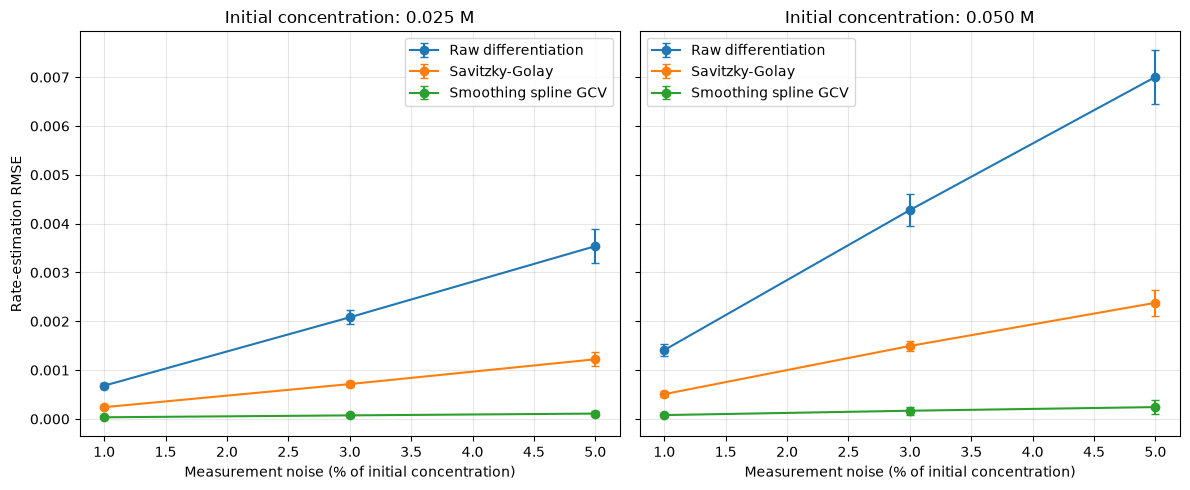

In [20]:
initial_concentrations = sorted(
    smooth_system_summary["Initial concentration"].unique()
)

fig, axes = plt.subplots(
    1, len(initial_concentrations),
    figsize=(6 * len(initial_concentrations), 5),
    sharey=True
)

for ax, ca0 in zip(np.atleast_1d(axes), initial_concentrations):
    for method in rate_method_columns:
        subset = smooth_system_summary.loc[
            (smooth_system_summary["Initial concentration"] == ca0)
            & (smooth_system_summary["Method"] == method)
        ].sort_values("Noise")

        ax.errorbar(
            subset["Noise"] * 100,
            subset["Mean_RMSE"],
            yerr=subset["SD_RMSE"],
            marker="o",
            capsize=3,
            label=method
        )

    ax.set_title(f"Initial concentration: {ca0:.3f} M")
    ax.set_xlabel("Measurement noise (% of initial concentration)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Rate-estimation RMSE")
plt.tight_layout()
plt.show()

## 13. Inspect a Representative Preprocessed Trajectory

The clean concentration is shown only as a visual evaluation reference. The three preprocessing methods receive the observed concentration alone.

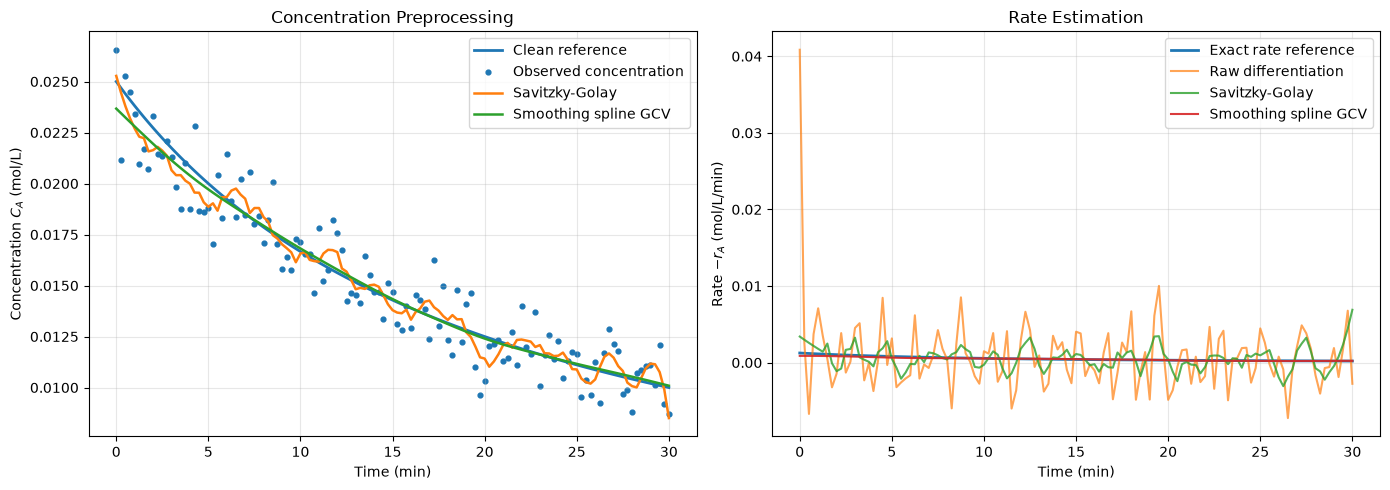

In [21]:
example_keys = {
    "reaction": "Second_Order",
    "initial_concentration_mol_L": TRAIN_INITIAL_CONCENTRATIONS[0],
    "noise_level": 0.05,
    "replicate": 1
}

example_processed = df_processed.loc[
    (df_processed["reaction"] == example_keys["reaction"])
    & (df_processed["initial_concentration_mol_L"] == example_keys["initial_concentration_mol_L"])
    & (df_processed["noise_level"] == example_keys["noise_level"])
    & (df_processed["replicate"] == example_keys["replicate"])
].copy()

example_truth = df.loc[
    (df["reaction"] == example_keys["reaction"])
    & (df["initial_concentration_mol_L"] == example_keys["initial_concentration_mol_L"])
    & (df["noise_level"] == example_keys["noise_level"])
    & (df["replicate"] == example_keys["replicate"]),
    ["time_min", "CA_true"]
]

example = example_processed.merge(
    example_truth,
    on="time_min",
    validate="one_to_one"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    example["time_min"],
    example["CA_true"],
    label="Clean reference",
    linewidth=2
)
axes[0].scatter(
    example["time_min"],
    example["CA_observed"],
    label="Observed concentration",
    s=12
)
axes[0].plot(
    example["time_min"],
    example["CA_sg"],
    label="Savitzky-Golay",
    linewidth=1.8
)
axes[0].plot(
    example["time_min"],
    example["CA_spline"],
    label="Smoothing spline GCV",
    linewidth=1.8
)
axes[0].set_xlabel("Time (min)")
axes[0].set_ylabel("Concentration $C_A$ (mol/L)")
axes[0].set_title("Concentration Preprocessing")
axes[0].grid(alpha=0.3)
axes[0].legend()

example_rate = df_evaluation.loc[
    (df_evaluation["reaction"] == example_keys["reaction"])
    & (df_evaluation["initial_concentration_mol_L"] == example_keys["initial_concentration_mol_L"])
    & (df_evaluation["noise_level"] == example_keys["noise_level"])
    & (df_evaluation["replicate"] == example_keys["replicate"])
].copy()

axes[1].plot(
    example_rate["time_min"],
    example_rate["rate_true"],
    label="Exact rate reference",
    linewidth=2
)
axes[1].plot(
    example_rate["time_min"],
    example_rate["rate_raw"],
    label="Raw differentiation",
    alpha=0.7
)
axes[1].plot(
    example_rate["time_min"],
    example_rate["rate_sg"],
    label="Savitzky-Golay",
    alpha=0.8
)
axes[1].plot(
    example_rate["time_min"],
    example_rate["rate_spline"],
    label="Smoothing spline GCV",
    alpha=0.9
)
axes[1].set_xlabel("Time (min)")
axes[1].set_ylabel("Rate $-r_A$ (mol/L/min)")
axes[1].set_title("Rate Estimation")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## 14. All-Reaction, All-Noise PySR Discovery

The earlier Section 14 was a single-condition pilot, which is why it showed only one reaction. This section now runs all six benchmark reactions at 1%, 3%, and 5% noise (18 conditions). For each condition, it fits Raw, Savitzky-Golay, and GCV PySR models (up to 54 searches total). Training uses initial concentrations 0.025 and 0.050 M, replicates 1-4. Replicate 5 at those concentrations selects equations; all replicates at 0.075 M are held out for final evaluation.

Do not use 0.075 M results to select preprocessing or equations. Within each preprocessing method, the one-standard-error rule favors a compact equation; a second one-standard-error rule compares the three method winners so small validation fluctuations do not force a method choice. The final tables compare the selected simplified candidate with its original PySR source on that untouched test condition.

### 14.1 Define the Full Benchmark Grid and Validation Split


In [22]:
RUN_REACTIONS = [
    "First_Order", "Second_Order", "Fractional_Order",
    "Saturation", "Fourth_Order", "Zero_Order"
]
RUN_NOISE_LEVELS = [0.01, 0.03, 0.05]
TRAIN_INITIAL_CONCENTRATIONS = [0.025, 0.05]
TEST_INITIAL_CONCENTRATION = 0.075
TRAINING_REPLICATES = [1, 2, 3, 4]
VALIDATION_REPLICATE = 5
MAX_PYSR_SOURCE_EQUATIONS = 30
SIMPLIFICATIONS_PER_SOURCE = 5

available_reactions = set(df_processed["reaction"].unique())
missing_reactions = set(RUN_REACTIONS) - available_reactions
if missing_reactions:
    raise ValueError(f"Reactions missing from processed data: {sorted(missing_reactions)}")
if not set(RUN_NOISE_LEVELS).issubset(set(df_processed["noise_level"].unique())):
    raise ValueError("One or more requested noise levels are missing from processed data.")

discovery_method_columns = {
    "Raw": ("CA_observed", "rate_raw"),
    "Savitzky-Golay": ("CA_sg", "rate_sg"),
    "GCV": ("CA_spline", "rate_spline")
}

### 14.2 Define Candidate Simplification and ODE Validation Helpers

Candidates are simplified and coefficient-refit using training data only. We then rank them by trajectory reconstruction on the validation replicate. For noisy-data training, observations below three standard deviations of the known synthetic measurement noise are excluded using measured CA; this avoids fitting the noise-dominated tail, including zero-order depletion. The threshold does not use CA_true.


In [23]:
def integrate_symbolic_rate(expression, time, initial_concentration):
    rate_function = sp.lambdify(x0, expression, modules="numpy")
    concentration_grid = np.linspace(max(initial_concentration * 1e-5, 1e-10), max(initial_concentration, 1e-10), 200)
    with np.errstate(all="ignore"):
        rates = np.asarray(rate_function(concentration_grid), dtype=float)
    if not np.all(np.isfinite(rates)) or np.any(rates < -1e-10):
        return None
    def rhs(_time, state):
        concentration = max(float(state[0]), 0.0)
        with np.errstate(all="ignore"):
            rate = float(rate_function(concentration))
        if not np.isfinite(rate) or rate < -1e-8:
            raise ValueError("Candidate gives a non-physical rate.")
        return [-max(rate, 0.0)]
    try:
        solution = solve_ivp(rhs, (float(time[0]), float(time[-1])), [float(initial_concentration)], t_eval=time, rtol=1e-7, atol=1e-10)
    except Exception:
        return None
    if not solution.success or solution.y.shape[1] != len(time) or not np.all(np.isfinite(solution.y[0])):
        return None
    return np.maximum(solution.y[0], 0.0)

def build_noisy_candidate_library(model, X_train, y_train):
    records = []
    source_rows = model.equations_.sort_values(["loss", "complexity"]).head(MAX_PYSR_SOURCE_EQUATIONS)
    for _, source_row in source_rows.iterrows():
        source = sp.sympify(source_row["sympy_format"])
        records.append({"Equation": source, "Source equation": source, "Candidate type": "PySR original", "Complexity": int(source_row["complexity"]), "Training Loss": float(source_row["loss"])})
        try:
            _, simplified = automatic_simplify(source, X_train, y_train)
        except (ValueError, TypeError, OverflowError):
            continue
        for _, candidate in simplified.head(SIMPLIFICATIONS_PER_SOURCE).iterrows():
            expression = sp.sympify(candidate["equation"])
            records.append({"Equation": expression, "Source equation": source, "Candidate type": "Simplified", "Complexity": int(candidate["complexity"]), "Training Loss": float(candidate["RSS"]) / len(y_train)})
    library = pd.DataFrame(records)
    library["_key"] = library["Equation"].map(lambda value: sp.srepr(sp.simplify(value)))
    return library.drop_duplicates(["_key", "Candidate type"]).drop(columns="_key").reset_index(drop=True)

def evaluate_trajectory_library(candidates, trajectories):
    validation_groups = [group.sort_values("time_min") for _, group in trajectories.groupby(["initial_concentration_mol_L", "replicate"], sort=False)]
    results = []
    for _, row in candidates.iterrows():
        expression = sp.factor(sp.cancel(sp.sympify(row["Equation"])))
        errors = []
        for group in validation_groups:
            time = group["time_min"].to_numpy(dtype=float)
            observed = group["CA_observed"].to_numpy(dtype=float)
            prediction = integrate_symbolic_rate(expression, time, float(observed[0]))
            if prediction is None:
                errors = []
                break
            errors.append(float(np.sqrt(np.mean((observed - prediction) ** 2))))
        if not errors:
            continue
        errors = np.asarray(errors, dtype=float)
        results.append({"Equation": expression, "Source equation": row["Source equation"], "Candidate type": row["Candidate type"], "Complexity": int(row["Complexity"]), "Training Loss": float(row["Training Loss"]), "Mean Trajectory RMSE": float(errors.mean()), "SE Trajectory RMSE": float(errors.std(ddof=1) / np.sqrt(len(errors))) if len(errors) > 1 else 0.0, "Validation Trajectories": int(len(errors))})
    if not results:
        return pd.DataFrame()
    return pd.DataFrame(results).sort_values(["Mean Trajectory RMSE", "Complexity"]).reset_index(drop=True)

def select_one_se_candidate(results):
    best = results.iloc[0]
    threshold = float(best["Mean Trajectory RMSE"] + best["SE Trajectory RMSE"])
    eligible = results.loc[results["Mean Trajectory RMSE"] <= threshold].sort_values(["Complexity", "Mean Trajectory RMSE", "Training Loss"])
    return eligible.iloc[0], float(threshold)


### 14.3 Fit and Select Equations for Every Reaction/Noise Pair

This cell runs the full grid. Expect up to 54 PySR fits. Training and validation use only 0.025/0.050 M; the 0.075 M trajectories are not read until the final evaluation block.


In [24]:
method_selection_rows = []
condition_selection_rows = []
heldout_metric_rows = []

for reaction in RUN_REACTIONS:
    for noise in RUN_NOISE_LEVELS:
        experiment = df_processed.loc[(df_processed["reaction"] == reaction) & np.isclose(df_processed["noise_level"], noise)].copy()
        train = experiment.loc[experiment["initial_concentration_mol_L"].isin(TRAIN_INITIAL_CONCENTRATIONS) & experiment["replicate"].isin(TRAINING_REPLICATES) & experiment["valid_interior"]].copy()
        validation = experiment.loc[experiment["initial_concentration_mol_L"].isin(TRAIN_INITIAL_CONCENTRATIONS) & (experiment["replicate"] == VALIDATION_REPLICATE)].copy()
        test_trajectories = experiment.loc[experiment["initial_concentration_mol_L"] == TEST_INITIAL_CONCENTRATION].copy()
        # Avoid fitting derivative noise where measured CA is below three known noise standard deviations.
        sigma_observed = noise * train["initial_concentration_mol_L"]
        train = train.loc[train["CA_observed"] > 3.0 * sigma_observed].copy()
        if train.empty or validation.empty or test_trajectories.empty:
            raise ValueError(f"Incomplete train/validation/test split for {reaction}, noise={noise}.")
        method_winners = []
        for method, (x_column, y_column) in discovery_method_columns.items():
            sigma = noise * train["initial_concentration_mol_L"].to_numpy(dtype=float)
            x_values = train[x_column].to_numpy(dtype=float)
            y_values = train[y_column].to_numpy(dtype=float)
            train_mask = np.isfinite(x_values) & np.isfinite(y_values) & (x_values > 3.0 * sigma)
            X_train = x_values[train_mask]
            y_train = y_values[train_mask]
            if len(X_train) < 20:
                raise ValueError(f"Too few usable training observations for {reaction}/{noise}/{method}: {len(X_train)}")
            model = create_pysr_model(verbosity=0)
            model.fit(X_train.reshape(-1, 1), y_train)
            candidate_library = build_noisy_candidate_library(model, X_train, y_train)
            validation_results = evaluate_trajectory_library(candidate_library, validation)
            if validation_results.empty:
                continue
            selected, one_se_threshold = select_one_se_candidate(validation_results)
            method_winner = selected.to_dict()
            method_winner.update({"Reaction": reaction, "Noise": float(noise), "Method": method, "One-SE Threshold": one_se_threshold, "Training Observations": int(len(X_train))})
            method_winners.append(method_winner)
            method_selection_rows.append(method_winner)
        if not method_winners:
            raise RuntimeError(f"No valid candidate for {reaction}, noise={noise}.")
        best_method = min(method_winners, key=lambda row: row["Mean Trajectory RMSE"])
        method_threshold = best_method["Mean Trajectory RMSE"] + best_method["SE Trajectory RMSE"]
        method_eligible = [row for row in method_winners if row["Mean Trajectory RMSE"] <= method_threshold]
        chosen = min(method_eligible, key=lambda row: (row["Complexity"], row["Mean Trajectory RMSE"], row["Training Loss"]))
        selected_equation = sp.sympify(chosen["Equation"])
        source_equation = sp.sympify(chosen["Source equation"])
        test_reference = df.loc[(df["reaction"] == reaction) & np.isclose(df["noise_level"], noise) & (df["initial_concentration_mol_L"] == TEST_INITIAL_CONCENTRATION), ["reaction", "initial_concentration_mol_L", "noise_level", "replicate", "time_min", "CA_true"]]
        test_data = test_trajectories.merge(test_reference, on=["reaction", "initial_concentration_mol_L", "noise_level", "replicate", "time_min"], how="inner", validate="one_to_one")
        for replicate, group in test_data.groupby("replicate", sort=True):
            group = group.sort_values("time_min")
            time = group["time_min"].to_numpy(dtype=float)
            observed = group["CA_observed"].to_numpy(dtype=float)
            true_ca = group["CA_true"].to_numpy(dtype=float)
            for label, expression in [("Original PySR source", source_equation), ("Validation-selected candidate", selected_equation)]:
                prediction = integrate_symbolic_rate(expression, time, float(observed[0]))
                if prediction is None:
                    continue
                heldout_metric_rows.append({"Reaction": reaction, "Noise": float(noise), "Replicate": int(replicate), "Candidate": label, "Observed RMSE": float(np.sqrt(np.mean((observed - prediction) ** 2))), "Clean-reference RMSE": float(np.sqrt(np.mean((true_ca - prediction) ** 2)))})
        condition_selection_rows.append({"Reaction": reaction, "Noise": float(noise), "Selected Method": chosen["Method"], "Candidate type": chosen["Candidate type"], "Selected Equation": str(selected_equation), "Source Equation": str(source_equation), "Complexity": int(chosen["Complexity"]), "Training Observations": int(chosen["Training Observations"]), "Validation Trajectory RMSE": float(chosen["Mean Trajectory RMSE"]), "Method One-SE Threshold": float(method_threshold), "Methods Within One-SE": ", ".join(row["Method"] for row in method_eligible)})
        print(f"Completed {reaction} at {noise:.0%} noise: {chosen['Method']} / {chosen['Candidate type']} / {selected_equation}", flush=True)

method_selection_df = pd.DataFrame(method_selection_rows)
condition_selection_df = pd.DataFrame(condition_selection_rows)
heldout_metrics_df = pd.DataFrame(heldout_metric_rows)


Completed First_Order at 1% noise: GCV / Simplified / 0.0999461468567*x0
Completed First_Order at 3% noise: GCV / Simplified / 0.0990351271015*x0
Completed First_Order at 5% noise: Raw / Simplified / 0.0976624984886*x0
Completed Second_Order at 1% noise: Raw / Simplified / 1.99972449932*x0**2
Completed Second_Order at 3% noise: GCV / Simplified / 1.95266955897*x0**2
Completed Second_Order at 5% noise: Savitzky-Golay / Simplified / 2.00426429317*x0**2
Completed Fractional_Order at 1% noise: Raw / Simplified / 0.464484067624*x0**1.5103469
Completed Fractional_Order at 3% noise: GCV / Simplified / 0.400775927448*x0**1.4718289
Completed Fractional_Order at 5% noise: GCV / Simplified / 0.346942555736*x0**1.4388525
Completed Saturation at 1% noise: Raw / Simplified / 0.00732662726940577*x0/(1.0*x0 + 0.021898013)
Completed Saturation at 3% noise: GCV / Simplified / 0.0227396114694*x0**0.49370572
Completed Saturation at 5% noise: GCV / Simplified / 0.0271920996827*x0**0.5440952
Completed Fourt

## 15. Summarize Validation and Held-Out Test Results

The final-test table is for reporting only. It must not be used to revise candidate selection. A negative simplification delta means the validation-selected candidate improved on its PySR source on the final test; a positive delta means simplification hurt.


,Equation,Source equation,Candidate type,Complexity,Training Loss,Mean Trajectory RMSE,SE Trajectory RMSE,Validation Trajectories,Reaction,Noise,Method,One-SE Threshold,Training Observations
0,0.0999461468567*x0,x0*(0.29520723 - (x0 + (x0 + x0 - 0.69189996)*(x0 + x0 + 0.08577087) + 0.25691)),Simplified,1,3.618694e-09,0.000420,0.000149,2,First_Order,0.01,GCV,0.000569,888
1,0.100508456843*x0,x0*(-2.2287786)*(x0*x0*(-1.6155319) - 0.043715212),Simplified,1,1.207330e-06,0.000425,0.000143,2,First_Order,0.01,Raw,0.000579,888
2,0.100246953299*x0,(-0.60133857 - 0.52190834/x0)*x0*x0*x0*(-0.36954302)/(x0 + x0) - 1*(-1.6325484e-5),Simplified,1,1.689657e-07,0.000422,0.000146,2,First_Order,0.01,Savitzky-Golay,0.000564,888
3,0.0990351271015*x0,(x0/(-0.20183523) + x0)*(x0*x0 - 1*0.025908098),Simplified,1,1.105430e-08,0.001216,0.000312,2,First_Order,0.03,GCV,0.001527,693
4,0.104812007268*x0,x0*(0.13767947 - x0*(x0/(x0 + x0 - 0.11310494) + 0.7283597))*0.73092747,Simplified,1,1.079144e-05,0.001283,0.000420,2,First_Order,0.03,Raw,0.001703,735
5,0.102550674327*x0,(-x0*x0/0.037517544 + x0 - 1*0.096327044)/((-0.8978399/x0)),Simplified,1,1.379604e-06,0.001224,0.000368,2,First_Order,0.03,Savitzky-Golay,0.001592,696
6,0.0983234596344*x0,(-x0*x0 + x0*0.59711003)*0.17265095,Simplified,1,1.372154e-07,0.002114,0.000656,2,First_Order,0.05,GCV,0.002733,543
7,0.0976624984886*x0,x0*(0.13777629 + x0*(-0.765078)) - 0.00041164595,Simplified,1,2.881748e-05,0.002112,0.000655,2,First_Order,0.05,Raw,0.002767,593
8,0.100286847327*x0,x0*((0.03426131 - x0)*(x0 + x0 + x0) - 1*(-0.101955086)) - 3.80659e-5,Simplified,1,3.528854e-06,0.002132,0.000663,2,First_Order,0.05,Savitzky-Golay,0.002792,551
9,807.268780968*x0**4,x0*x0*x0/(0.042609736*((0.029073425/x0))),Simplified,2,4.989329e-09,0.000388,0.000145,2,Fourth_Order,0.01,GCV,0.000531,888


,Reaction,Noise,Selected Method,Candidate type,Selected Equation,Source Equation,Complexity,Training Observations,Validation Trajectory RMSE,Method One-SE Threshold,Methods Within One-SE,Mean_Observed_RMSE | Original PySR source,Mean_Observed_RMSE | Validation-selected candidate,Mean_Clean_RMSE | Original PySR source,Mean_Clean_RMSE | Validation-selected candidate,Clean_RMSE_Delta_Selected_minus_Source,Observed_RMSE_Delta_Selected_minus_Source
0,First_Order,0.01,GCV,Simplified,0.0999461468567*x0,x0*(0.29520723 - (x0 + (x0 + x0 - 0.69189996)*(x0 + x0 + 0.08577087) + 0.25691)),1,888,0.000420,0.000568,"Raw, Savitzky-Golay, GCV",0.000980,0.000760,0.000684,0.000216,-4.682442e-04,-2.203635e-04
1,First_Order,0.03,GCV,Simplified,0.0990351271015*x0,(x0/(-0.20183523) + x0)*(x0*x0 - 1*0.025908098),1,693,0.001216,0.001527,"Raw, Savitzky-Golay, GCV",0.002875,0.002501,0.001846,0.001176,-6.698718e-04,-3.742147e-04
2,First_Order,0.05,Raw,Simplified,0.0976624984886*x0,x0*(0.13777629 + x0*(-0.765078)) - 0.00041164595,1,593,0.002112,0.002767,"Raw, Savitzky-Golay, GCV",NaN,0.004048,NaN,0.001329,NaN,NaN
3,Fourth_Order,0.01,Savitzky-Golay,Simplified,801.565154459*x0**4,x0*x0*(x0 + 16.818089)*(x0 + 2.281556)*x0*0.40378302*50.778603*x0,2,888,0.000378,0.000514,"Raw, Savitzky-Golay, GCV",0.000780,0.000780,0.000075,0.000062,-1.304810e-05,-1.869923e-08
4,Fourth_Order,0.03,Raw,Simplified,765.820309957*x0**4,x0*x0*(x0 + x0*x0*739.2378),2,888,0.001128,0.001535,"Raw, Savitzky-Golay, GCV",0.002383,0.002374,0.000495,0.000461,-3.361814e-05,-8.928990e-06
5,Fourth_Order,0.05,GCV,Simplified,27.4275873165*x0**3,x0*x0*(x0 + x0 - 0.027290644 + 0.00013829146)*1.1511668/0.050504405,2,888,0.002213,0.002363,"Raw, Savitzky-Golay, GCV",NaN,0.004809,NaN,0.002996,NaN,NaN
6,Fractional_Order,0.01,Raw,Simplified,0.464484067624*x0**1.5103469,x0**1.5103469*0.6117713*0.7628379,2,888,0.000388,0.000512,"Raw, Savitzky-Golay, GCV",0.000812,0.000801,0.000339,0.000297,-4.288913e-05,-1.123980e-05
7,Fractional_Order,0.03,GCV,Simplified,0.400775927448*x0**1.4718289,x0**1.4718289*0.40076452*0.58899105/0.58899105,2,888,0.001205,0.001516,"Raw, Savitzky-Golay, GCV",0.002238,0.002238,0.000394,0.000394,-2.180113e-07,-1.261591e-08
8,Fractional_Order,0.05,GCV,Simplified,0.346942555736*x0**1.4388525,(x0*(-0.5207289) + x0)**1.4388525,2,859,0.002186,0.002677,"Raw, Savitzky-Golay, GCV",0.004082,0.004083,0.001522,0.001525,2.668663e-06,1.282211e-06
9,Saturation,0.01,Raw,Simplified,0.00732662726940577*x0/(1.0*x0 + 0.021898013),x0/(((x0 + 0.021898013)/0.0073084054)) + 1.47457495e-5,4,458,0.000408,0.000508,"Raw, Savitzky-Golay",0.000922,0.000919,0.000509,0.000500,-8.795491e-06,-3.253458e-06


,Noise,Method,Mean_Validation_RMSE,SD_Validation_RMSE,Conditions
0,0.01,GCV,0.000411,0.000057,6
1,0.01,Raw,0.000392,0.000025,6
2,0.01,Savitzky-Golay,0.000399,0.000031,6
3,0.03,GCV,0.001176,0.000037,6
4,0.03,Raw,0.001232,0.000072,6
5,0.03,Savitzky-Golay,0.001238,0.000109,6
6,0.05,GCV,0.002157,0.000060,6
7,0.05,Raw,0.002171,0.000105,6
8,0.05,Savitzky-Golay,0.002103,0.000162,6


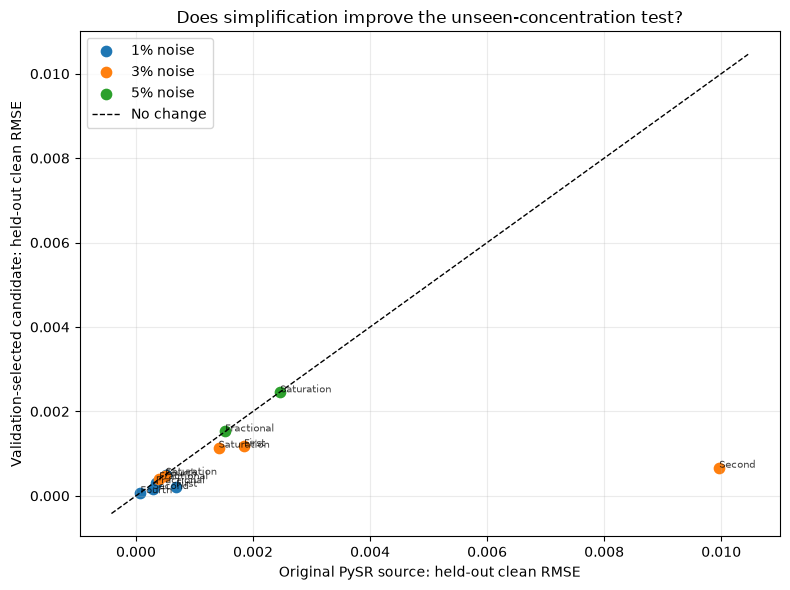

Saved summary CSV files to: C:\F\CHE657 Term Project\outputs\all_laws_three_noise_levels


In [25]:
display(method_selection_df.sort_values(["Reaction", "Noise", "Method"]).reset_index(drop=True))
heldout_means = (heldout_metrics_df.groupby(["Reaction", "Noise", "Candidate"]).agg(Mean_Observed_RMSE=("Observed RMSE", "mean"), SD_Observed_RMSE=("Observed RMSE", "std"), Mean_Clean_RMSE=("Clean-reference RMSE", "mean"), SD_Clean_RMSE=("Clean-reference RMSE", "std")).reset_index())
heldout_wide = heldout_means.pivot(index=["Reaction", "Noise"], columns="Candidate", values=["Mean_Observed_RMSE", "Mean_Clean_RMSE"])
expected_columns = pd.MultiIndex.from_product([["Mean_Observed_RMSE", "Mean_Clean_RMSE"], ["Original PySR source", "Validation-selected candidate"]])
heldout_wide = heldout_wide.reindex(columns=expected_columns)
heldout_wide.columns = [f"{metric} | {candidate}" for metric, candidate in heldout_wide.columns]
condition_results_df = condition_selection_df.merge(heldout_wide.reset_index(), on=["Reaction", "Noise"], how="left", validate="one_to_one")
condition_results_df["Clean_RMSE_Delta_Selected_minus_Source"] = condition_results_df["Mean_Clean_RMSE | Validation-selected candidate"] - condition_results_df["Mean_Clean_RMSE | Original PySR source"]
condition_results_df["Observed_RMSE_Delta_Selected_minus_Source"] = condition_results_df["Mean_Observed_RMSE | Validation-selected candidate"] - condition_results_df["Mean_Observed_RMSE | Original PySR source"]
display(condition_results_df.sort_values(["Reaction", "Noise"]).reset_index(drop=True))
summary_by_noise_method = method_selection_df.groupby(["Noise", "Method"]).agg(Mean_Validation_RMSE=("Mean Trajectory RMSE", "mean"), SD_Validation_RMSE=("Mean Trajectory RMSE", "std"), Conditions=("Reaction", "count")).reset_index()
display(summary_by_noise_method)
fig, ax = plt.subplots(figsize=(8, 6))
for noise, group in condition_results_df.groupby("Noise"):
    x = group["Mean_Clean_RMSE | Original PySR source"]
    y = group["Mean_Clean_RMSE | Validation-selected candidate"]
    ax.scatter(x, y, label=f"{noise:.0%} noise", s=55)
    for _, row in group.iterrows():
        ax.annotate(row["Reaction"].replace("_Order", ""), (row["Mean_Clean_RMSE | Original PySR source"], row["Mean_Clean_RMSE | Validation-selected candidate"]), fontsize=7, alpha=0.75)
limits = ax.get_xlim()
ax.plot(limits, limits, "k--", linewidth=1, label="No change")
ax.set(xlabel="Original PySR source: held-out clean RMSE", ylabel="Validation-selected candidate: held-out clean RMSE", title="Does simplification improve the unseen-concentration test?")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()
results_dir = Path("outputs") / "all_laws_three_noise_levels"
results_dir.mkdir(parents=True, exist_ok=True)
method_selection_df.to_csv(results_dir / "method_validation_results.csv", index=False)
condition_results_df.to_csv(results_dir / "condition_and_test_summary.csv", index=False)
heldout_metrics_df.to_csv(results_dir / "heldout_replicate_metrics.csv", index=False)
print("Saved summary CSV files to:", results_dir.resolve())


## 16. How to Interpret the Full Benchmark

The saved first-order 5% pilot selected GCV and reported equation 0.0985864 * CA, with mean observed-data RMSE 0.004076 and mean clean-reference RMSE 0.001303. That is one condition only; it is retained here as a pilot reference, not as the full study. The full grid above has not been run in this notebook yet.

Compare the 18 selected equations and the 54 method-validation rows. Rate-estimation metrics in Section 12 use known rates only for retrospective preprocessing evaluation. Model training uses observed CA and numerical rates; observations below three known noise standard deviations are excluded from training to avoid fitting the noise-dominated tail. Candidate selection uses replicate 5; final accuracy uses CA0 = 0.075 M only after selection. Ground-truth zero-order depletion masking is confined to retrospective scoring.